<a href="https://colab.research.google.com/github/niofrequency/google-collab_image/blob/main/BIGLUST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content
!git clone https://github.com/comfyanonymous/ComfyUI /content/ComfyUI
!git clone https://github.com/city96/ComfyUI-GGUF /content/ComfyUI/custom_nodes/ComfyUI-GGUF
!pip install -q torchsde gguf
!pip install -q -r /content/ComfyUI/requirements.txt
!apt install aria2 -qqy

# Download BigLust (SDXL checkpoint)
!mkdir -p /content/ComfyUI/models/checkpoints
!wget -q --show-progress -O /content/ComfyUI/models/checkpoints/biglust.safetensors \
  "https://civitai.com/api/download/models/1081768?fileId=986850&token=777a5632707c15ecf54e13eb3b1b862b"

# Download VAE (SDXL VAE is recommended for BigLust)
!mkdir -p /content/ComfyUI/models/vae
!aria2c --console-log-level=error -c -x 16 -s 16 -k 1M \
  https://huggingface.co/stabilityai/sdxl-vae/resolve/main/sdxl_vae.safetensors \
  -d /content/ComfyUI/models/vae -o sdxl_vae.safetensors


# Check downloads
!ls -lh /content/ComfyUI/models/checkpoints/
!ls -lh /content/ComfyUI/models/loras/
!ls -lh /content/ComfyUI/models/vae/

/content
fatal: destination path '/content/ComfyUI' already exists and is not an empty directory.
fatal: destination path '/content/ComfyUI/custom_nodes/ComfyUI-GGUF' already exists and is not an empty directory.
aria2 is already the newest version (1.37.0+debian-1build3).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
/content/ComfyUI/mo 100%[===================>]   6.46G  66.1MB/s    in 2m 2s   

Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
0f6941|OK  |       0B/s|/content/ComfyUI/models/vae/sdxl_vae.safetensors

Status Legend:
(OK):download completed.
total 6.5G
-rw-r--r-- 1 root root 6.5G Jul 11 16:33 biglust.safetensors
-rw-r--r-- 1 root root    0 Nov 10 14:20 put_checkpoints_here
total 0
-rw-r--r-- 1 root root 0 Nov 10 14:20 put_loras_here
total 320M
-rw-r--r-- 1 root root    0 Nov 10 14:20 put_vae_here
-rw-r--r-- 1 root root 320M Nov 10 14:23 sdxl_vae.safetensors


In [3]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
import logging
import warnings

# Hide warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

from nodes import NODE_CLASS_MAPPINGS

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
VAELoader = NODE_CLASS_MAPPINGS["VAELoader"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()

with torch.inference_mode():
    # Load BigLust checkpoint
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

print("BigLust loaded.")
print("Sampler will be dpmpp_2m + karras in Cell 3.")

/content/ComfyUI
BigLust loaded.
Sampler will be dpmpp_2m + karras in Cell 3.


/content/ComfyUI


  0%|          | 0/25 [00:00<?, ?it/s]

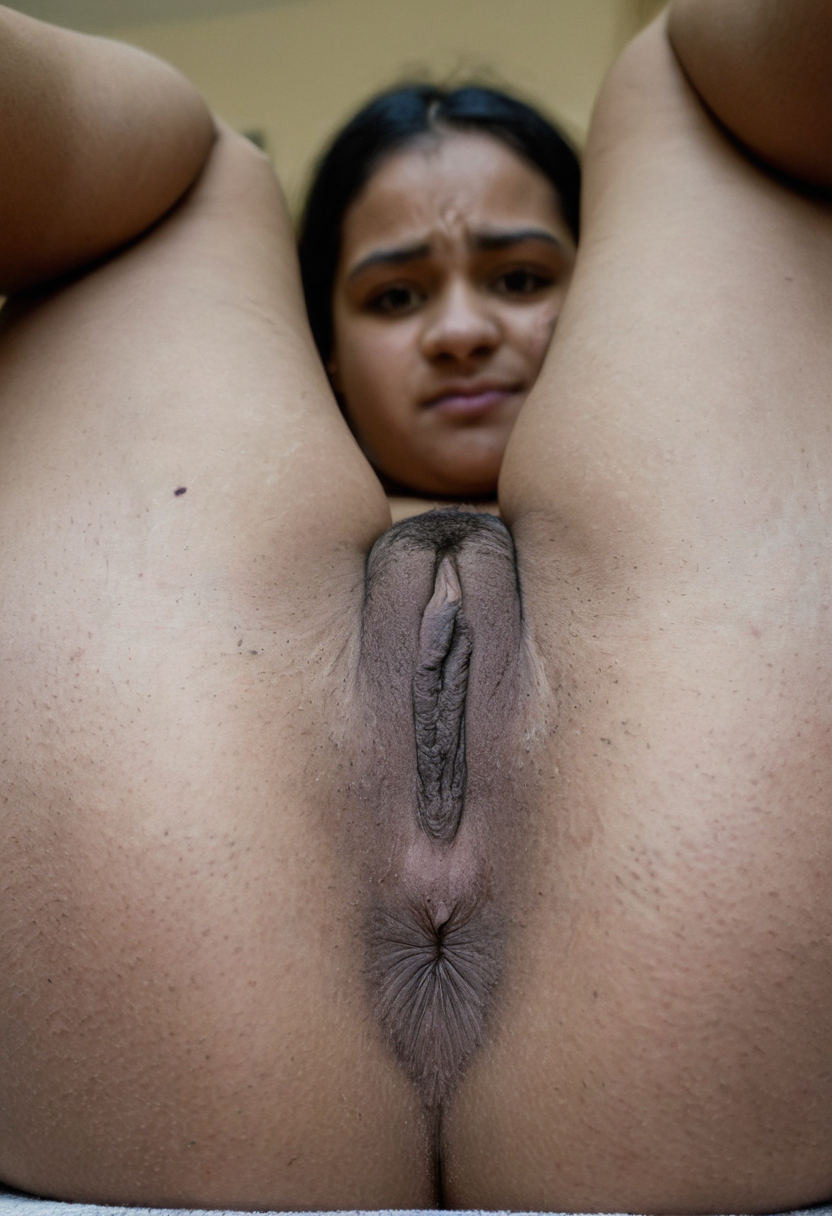

Saved to /content/test.png


In [ ]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
from IPython.display import display
from nodes import NODE_CLASS_MAPPINGS
import logging
import warnings

# Hide the LoRA key warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()

with torch.inference_mode():
    # Load BigLust
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

    # Apply LoRAs
    lora = LoraLoaderModelOnly.load_lora_model_only(unet, "pussy.safetensors", 1.0)[0]
    lora = LoraLoaderModelOnly.load_lora_model_only(lora, "skin.safetensors", 0.8)[0]

    seed = 0
    steps = 25
    cfg = 4.5
    sampler_name = "dpmpp_2m"
    scheduler = "karras"
    width = 832
    height = 1216

    positive_prompt = "Her full face and vagina in the shot, chubby latina woman holding her thick thighs, medium close-up, low-angle perspective from between the legs of a naked Latina woman. Highly detailed natural vulva, realistic labia majora and minora with natural folds, asymmetry and texture, visible clitoral hood, realistic pubic hair that is not perfectly trimmed, subtle natural moisture and skin sheen only on the genitals, visible pores, fine skin texture, slight natural imperfections, not smooth, not plastic. The woman is holding her legs up, spreading wide, looking down at the camera with a seductive expression. Shallow depth of field, raw photograph, highly detailed anatomy, photorealistic skin texture, 8k, natural lighting"
    negative_prompt = "plastic skin, glossy skin, oily skin, waxy skin, airbrushed, over-smoothed, excessive shine, artificial wetness, cgi, 3d render, doll-like, smooth skin, bright red labia, cartoon vulva, artificial anatomy, 色调艳丽，过曝，静态，细节模糊不清，字幕，风格，作品，画作，画面，静止，整体发灰，最差质量，低质量，JPEG压缩残留，丑陋的，残缺的，多余的手指，画得不好的手部，画得不好的脸部，畸形的，毁容的，形态畸形的肢体，手指融合，静止不动的画面，杂乱的背景，三条腿，背景人很多，倒着走"

    positive = CLIPTextEncode.encode(clip, positive_prompt)[0]
    negative = CLIPTextEncode.encode(clip, negative_prompt)[0]
    latent_image = EmptyLatentImage.generate(width, height)[0]

    if seed == 0:
        random.seed(int(time.time()))
        seed = random.randint(0, 18446744073709551615)

    samples = KSampler.sample(lora, seed, steps, cfg, sampler_name, scheduler, positive, negative, latent_image)[0]
    decoded = VAEDecode.decode(vae, samples)[0].detach()

    img_array = (decoded.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)[0]
    image = Image.fromarray(img_array)
    image.save("/content/test.png")
    display(image)

print("Saved to /content/test.png")

In [ ]:
# ========== BigLust API + Cloudflare Tunnel ==========
%cd /content/ComfyUI

!pip install -q fastapi uvicorn python-multipart requests
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /tmp/cloudflared
!chmod +x /tmp/cloudflared

from fastapi import FastAPI, Request
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import JSONResponse
from pydantic import BaseModel
from typing import List, Optional
import base64
from io import BytesIO
import subprocess
import time
import re
import threading
import torch
import random
from PIL import Image
import numpy as np
import requests
import os
from collections import defaultdict
from nodes import NODE_CLASS_MAPPINGS

# Nodes
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()

app = FastAPI()

# Stronger CORS
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["GET", "POST", "OPTIONS", "PUT", "DELETE"],
    allow_headers=["*"],
    expose_headers=["*"],
)

# Extra CORS headers on every response
@app.middleware("http")
async def add_cors_headers(request: Request, call_next):
    if request.method == "OPTIONS":
        return JSONResponse(
            content={},
            headers={
                "Access-Control-Allow-Origin": "*",
                "Access-Control-Allow-Methods": "GET, POST, OPTIONS, PUT, DELETE",
                "Access-Control-Allow-Headers": "*",
            }
        )
    response = await call_next(request)
    response.headers["Access-Control-Allow-Origin"] = "*"
    response.headers["Access-Control-Allow-Methods"] = "GET, POST, OPTIONS, PUT, DELETE"
    response.headers["Access-Control-Allow-Headers"] = "*"
    return response

user_data = defaultdict(lambda: {"loras": [], "checkpoints": []})

class LoraItem(BaseModel):
    name: str
    strength: float = 1.0

class GenerateRequest(BaseModel):
    checkpoint: Optional[str] = None
    sampler: str = "dpmpp_2m"
    scheduler: str = "karras"
    steps: int = 25
    cfg: float = 4.5
    width: int = 832
    height: int = 1216
    loras: List[LoraItem] = []
    positive: str
    negative: str

class ModelDownload(BaseModel):
    url: str
    type: str

def get_user_ip(request: Request):
    forwarded = request.headers.get("x-forwarded-for")
    if forwarded:
        return forwarded.split(",")[0].strip()
    return request.client.host

@app.post("/generate")
async def generate(req: GenerateRequest, request: Request):
    try:
        with torch.inference_mode():
            if req.checkpoint:
                ckpt = CheckpointLoaderSimple.load_checkpoint(req.checkpoint)
                current_model = ckpt[0]
                clip_to_use = ckpt[1]
                vae_to_use = ckpt[2]
            else:
                current_model = unet
                clip_to_use = clip
                vae_to_use = vae

            for lora_item in req.loras:
                if lora_item.name and lora_item.strength > 0:
                    current_model = LoraLoaderModelOnly.load_lora_model_only(
                        current_model,
                        lora_item.name,
                        float(lora_item.strength)
                    )[0]

            positive = CLIPTextEncode.encode(clip_to_use, req.positive)[0]
            negative = CLIPTextEncode.encode(clip_to_use, req.negative)[0]
            latent_image = EmptyLatentImage.generate(req.width, req.height)[0]

            seed = random.randint(0, 18446744073709551615)
            samples = KSampler.sample(
                current_model, seed, req.steps, req.cfg,
                req.sampler, req.scheduler,
                positive, negative, latent_image
            )[0]

            decoded = VAEDecode.decode(vae_to_use, samples)[0].detach()
            img_array = (decoded.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)[0]
            image = Image.fromarray(img_array)

            buffer = BytesIO()
            image.save(buffer, format="PNG")
            img_b64 = base64.b64encode(buffer.getvalue()).decode()

            return {"image": f"data:image/png;base64,{img_b64}", "seed": seed}
    except Exception as e:
        return {"error": str(e)}

@app.post("/download_model")
def download_model(req: ModelDownload, request: Request):
    try:
        ip = get_user_ip(request)
        filename = req.url.split("/")[-1].split("?")[0]

        if req.type == "lora":
            if not filename.endswith(".safetensors"):
                filename = f"lora_{int(time.time())}.safetensors"
            path = f"/content/ComfyUI/models/loras/{filename}"
        else:
            if not filename.endswith((".safetensors", ".ckpt")):
                filename = f"model_{int(time.time())}.safetensors"
            path = f"/content/ComfyUI/models/checkpoints/{filename}"

        os.makedirs(os.path.dirname(path), exist_ok=True)
        r = requests.get(req.url, timeout=300)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)

        if req.type == "lora":
            if filename not in [l["name"] for l in user_data[ip]["loras"]]:
                user_data[ip]["loras"].append({"name": filename, "strength": 0.8})
        else:
            if filename not in user_data[ip]["checkpoints"]:
                user_data[ip]["checkpoints"].append(filename)

        return {"filename": filename, "type": req.type}
    except Exception as e:
        return {"error": str(e)}

@app.get("/user_models")
def get_user_models(request: Request):
    ip = get_user_ip(request)
    return user_data[ip]

@app.get("/")
def root():
    return {"status": "ok"}

def start_server():
    import uvicorn
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="warning")

# Clear old processes
!fuser -k 8000/tcp || true
!pkill -f cloudflared || true
time.sleep(2)

# Start server
threading.Thread(target=start_server, daemon=True).start()
print("Waiting for server to start...")
time.sleep(6)

print("Starting Cloudflare tunnel...")
proc = subprocess.Popen(
    ["/tmp/cloudflared", "tunnel", "--url", "http://localhost:8000"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

public_url = None
for _ in range(50):
    line = proc.stdout.readline()
    if not line:
        time.sleep(0.5)
        continue
    print(line.strip())
    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        public_url = match.group(0)
        break

if public_url:
    print("\n" + "="*60)
    print("BACKEND READY")
    print(f"Paste this into the frontend Backend URL field:\n{public_url}")
    print("="*60)
    print(f"Test docs: {public_url}/docs")
else:
    print("Tunnel failed.")

/content/ComfyUI
^C


INFO:     Started server process [88385]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


Waiting for server...
Starting Cloudflare tunnel...
2026-11-10T06:47:26Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-10T06:47:26Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-10T06:47:29Z INF +--------------------------------------------------------------------------------------------+
2026-11-10T06:47:29Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-10T06:47:29Z INF |  h